# 02 · Preprocesamiento — Predicción de reingreso <30 días (diabetes)

**Proyecto:** `diabetes-readmission-predictor` · Aprendizaje de Máquina (UIS)

Este notebook deja el dataset listo para modelar **sin fuga de datos (data leakage)** y documenta cada decisión.
Cubre los requisitos del proyecto que dependen del preprocesamiento:

| Requisito | Dónde se resuelve |
|---|---|
| Analizar los datos (con gráficas) | §6 (solo sobre *train*) |
| Cómo se escalaron los datos | §7 |
| Características definitivas | §8 |
| Métrica objetivo | §9 |
| Garantías anti-leakage | §10 |
| Artefactos para el siguiente notebook | §11 |
| 4 modelos (GNB, DT, RF, SVM), hiperparámetros, elección del mejor y su justificación | `03_modeling` / `04_evaluation` (consumen los artefactos de §11) |

## Reglas anti-leakage que sigue este notebook

1. **Primero se filtra y se divide; después se aprende nada de los datos.** Imputación, escalado, agrupación de categorías raras y selección de variables se ajustan **solo con *train***.
2. Todo lo que "aprende" vive dentro de un `Pipeline`/`ColumnTransformer` de scikit-learn.
3. **Un encuentro por paciente** (el primero) → no hay pacientes repetidos entre *train* y *test*.
4. Se excluyen altas por fallecimiento/hospicio (esos pacientes no pueden reingresar).
5. La columna `readmitted` original se elimina de las features (es el target).
6. El **test queda congelado**: se guarda en disco y no se usa hasta la evaluación final.
7. La selección de variables se hace con **validación cruzada dentro de *train***.

## 0. Configuración

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
TARGET = "readmitted_lt30"
N_FOLDS = 5          # folds de CV dentro de train
PERM_REPEATS = 3     # repeticiones de la importancia por permutación

In [2]:
def find_project_root() -> Path:
    """Busca la carpeta del repo (la que contiene data/raw/diabetic_data.csv).
    Funciona en local (notebooks/ dentro del repo) y en Colab."""
    candidates = [
        Path.cwd(), *Path.cwd().parents,
        Path("/content/diabetes-readmission-predictor"),
        Path("/content/diabetes-readmission-predictor/diabetes-readmission-predictor"),
    ]
    for p in candidates:
        if (p / "data" / "raw" / "diabetic_data.csv").exists():
            return p
    raise FileNotFoundError(
        "No encuentro data/raw/diabetic_data.csv. Sube el CSV a data/raw/ del repo o ajusta ROOT a mano."
    )

ROOT = find_project_root()
RAW, PROC, ART, FIG = ROOT / "data/raw", ROOT / "data/processed", ROOT / "artifacts", ROOT / "reports/figures"
for d in (PROC, ART, FIG):
    d.mkdir(parents=True, exist_ok=True)

def savefig(name: str) -> None:
    plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")

print("ROOT:", ROOT)

ROOT: /home/claude/proj


## 1. Carga correcta de los datos

**Trampa clásica de este dataset:** los faltantes reales vienen como `"?"`, pero pandas *además* interpreta el texto `"None"` como NaN.
En `A1Cresult` y `max_glu_serum`, `"None"` significa **"el examen no se midió"**, que es información clínica (un médico que no pide HbA1c dice algo del paciente), no un faltante.
Si se pierde esa distinción, estas columnas parecen 83% y 95% vacías y se tiran por error.

Por eso se carga con `keep_default_na=False` y **solo `"?"` como NaN**.

In [3]:
CSV = RAW / "diabetic_data.csv"

# Carga correcta: solo "?" es faltante
df_raw = pd.read_csv(CSV, na_values=["?"], keep_default_na=False, low_memory=False)

# Demostración del problema (carga con los NaN por defecto de pandas)
cols_none = ["A1Cresult", "max_glu_serum"]
df_bug = pd.read_csv(CSV, na_values=["?"], low_memory=False, usecols=cols_none)

comparacion = pd.DataFrame({
    "% NaN con defaults de pandas (incorrecto)": df_bug.isna().mean() * 100,
    "% NaN carga correcta": df_raw[cols_none].isna().mean() * 100,
}).round(1)
display(comparacion)

print(f"Filas: {len(df_raw):,} | Columnas: {df_raw.shape[1]}")
print("Strings vacíos en columnas de texto:", int((df_raw.select_dtypes(exclude="number") == "").sum().sum()))
print("\nValores de A1Cresult:", df_raw["A1Cresult"].value_counts(dropna=False).to_dict())

,% NaN con defaults de pandas (incorrecto),% NaN carga correcta
A1Cresult,83.3,0.0
max_glu_serum,94.7,0.0


Filas: 101,766 | Columnas: 50


Strings vacíos en columnas de texto: 0

Valores de A1Cresult: {'None': 84748, '>8': 8216, 'Norm': 4990, '>7': 3812}


In [4]:
faltantes = (df_raw.isna().mean() * 100).round(2)
faltantes = faltantes[faltantes > 0].sort_values(ascending=False).to_frame("% faltante real")
display(faltantes)

,% faltante real
weight,96.86
medical_specialty,49.08
payer_code,39.56
race,2.23
diag_3,1.40
diag_2,0.35
diag_1,0.02


**Lectura:** con la carga correcta, los faltantes reales quedan en `weight` (~97%), `medical_specialty` (~49%), `payer_code` (~40%), `race` (~2%) y los `diag_*`.
`A1Cresult` y `max_glu_serum` **ya no tienen faltantes**: `"None"` pasa a ser una categoría más ("no medido").

## 2. Filtros de filas y target (antes del split)

Estas operaciones **no aprenden nada de los datos** (son reglas fijas), por eso es seguro hacerlas antes de dividir.

El orden importa:

1. **Primer encuentro por paciente** (ordenando por `encounter_id`; el dataset no trae fecha, así que se asume que un `encounter_id` menor es anterior).
2. **Quitar altas por fallecimiento/hospicio** (`discharge_disposition_id` ∈ {11, 13, 14, 19, 20, 21}). Se hace *después* del paso 1: si se hiciera antes, un paciente cuyo primer encuentro terminó en muerte "saltaría" a su segundo encuentro y se sesgaría la muestra.
3. Quitar las 3 filas con `gender = Unknown/Invalid`.
4. Target binario: `1` = reingreso `<30` días, `0` = resto (`>30` o `NO`).

In [5]:
TERMINAL_DISCHARGES = {11, 13, 14, 19, 20, 21}   # fallecido u hospicio

def keep_first_encounter(df: pd.DataFrame) -> pd.DataFrame:
    return df.sort_values("encounter_id").drop_duplicates("patient_nbr", keep="first")

def drop_terminal_discharges(df: pd.DataFrame) -> pd.DataFrame:
    return df[~df["discharge_disposition_id"].isin(TERMINAL_DISCHARGES)]

def drop_invalid_gender(df: pd.DataFrame) -> pd.DataFrame:
    return df[df["gender"] != "Unknown/Invalid"]

def build_target(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out[TARGET] = (out["readmitted"] == "<30").astype(int)
    return out

pasos = [
    ("Dataset crudo", lambda d: d),
    ("1) Primer encuentro por paciente", keep_first_encounter),
    ("2) Sin altas por fallecimiento/hospicio", drop_terminal_discharges),
    ("3) Sin género inválido", drop_invalid_gender),
]
traza, actual = [], df_raw
for nombre, fn in pasos:
    actual = fn(actual)
    traza.append({"paso": nombre, "filas": len(actual), "pacientes únicos": actual["patient_nbr"].nunique(),
                  "% reingreso <30": round((actual["readmitted"] == "<30").mean() * 100, 2)})
df = build_target(actual)
display(pd.DataFrame(traza))

assert df["patient_nbr"].is_unique, "quedan pacientes repetidos"
assert not df["discharge_disposition_id"].isin(TERMINAL_DISCHARGES).any()
assert set(df[TARGET].unique()) == {0, 1}
print("✔ Filtros verificados: un encuentro por paciente, sin altas terminales, target binario.")

,paso,filas,pacientes únicos,% reingreso <30
0,Dataset crudo,101766,71518,11.16
1,1) Primer encuentro por paciente,71518,71518,8.80
2,2) Sin altas por fallecimiento/hospicio,69973,69973,8.97
3,3) Sin género inválido,69970,69970,8.97


✔ Filtros verificados: un encuentro por paciente, sin altas terminales, target binario.


## 3. Limpieza de columnas y tipos

- **Se eliminan:** `weight` (~97% faltante), `payer_code` (~40% faltante y poco relacionado con lo clínico), columnas **constantes** (se detectan automáticamente) y `readmitted` (es el target original: dejarlo sería fuga directa).
- **Identificadores:** `encounter_id` pasa a ser el índice y `patient_nbr` se guarda aparte (solo sirve para comprobar que no hay solapamiento entre *train* y *test*; **no es feature**).
- **`admission_type_id`, `discharge_disposition_id`, `admission_source_id` son categorías**, no números (el 7 no es "más" que el 3). Se convierten a texto, y los códigos que según `IDS_mapping.csv` significan *Not Available / NULL / Not Mapped / Unknown* se agrupan en `"Unknown"`.
- **`age`** tiene 10 rangos con orden natural → se codifica como ordinal `age_ord` (0 = [0-10) … 9 = [90-100)).

In [6]:
DROP_COLS = ["weight", "payer_code", "readmitted"]
UNKNOWN_IDS = {
    "admission_type_id": {5, 6, 8},
    "admission_source_id": {9, 15, 17, 20, 21},
    "discharge_disposition_id": {18, 25, 26},
}
AGE_ORDER = {f"[{i}-{i + 10})": i // 10 for i in range(0, 100, 10)}

def tidy_columns(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Devuelve (datos con índice encounter_id, serie patient_nbr)."""
    out = df.copy()
    constantes = [c for c in out.columns if out[c].nunique(dropna=False) == 1]
    print("Columnas constantes eliminadas:", constantes)

    for col, codigos in UNKNOWN_IDS.items():
        out[col] = out[col].map(lambda v, cs=codigos: "Unknown" if v in cs else str(v))

    assert out["age"].isin(AGE_ORDER).all(), "rango de edad inesperado"
    out["age_ord"] = out["age"].map(AGE_ORDER)

    out = out.drop(columns=DROP_COLS + constantes + ["age"])
    out = out.set_index("encounter_id")
    patient = out.pop("patient_nbr")
    return out, patient

data, patient_id = tidy_columns(df)
print(f"Dataset tras limpieza: {data.shape[0]:,} filas × {data.shape[1]} columnas (incluye el target)")

Columnas constantes eliminadas: ['examide', 'citoglipton', 'glimepiride-pioglitazone']


Dataset tras limpieza: 69,970 filas × 43 columnas (incluye el target)


## 4. Agrupación de diagnósticos ICD-9

`diag_1/2/3` tienen ~700-800 códigos distintos: inutilizables tal cual (y rompen el χ²). Se agrupan en categorías clínicas siguiendo **Strack et al. (2014)**.
Detalles que rompen implementaciones ingenuas:

- Los códigos con prefijo **`V`** (factores de salud) y **`E`** (causas externas) no son numéricos → van a `"Other"`.
- `250.xx` (diabetes) es su propia categoría.
- Los NaN se mantienen como `"Missing"` (que falte el diagnóstico secundario es informativo).

Es una regla fija (no aprende de los datos), así que puede ir antes del split. Se prueba con ejemplos conocidos.

✔ Mapeo ICD-9 verificado en 17 casos.


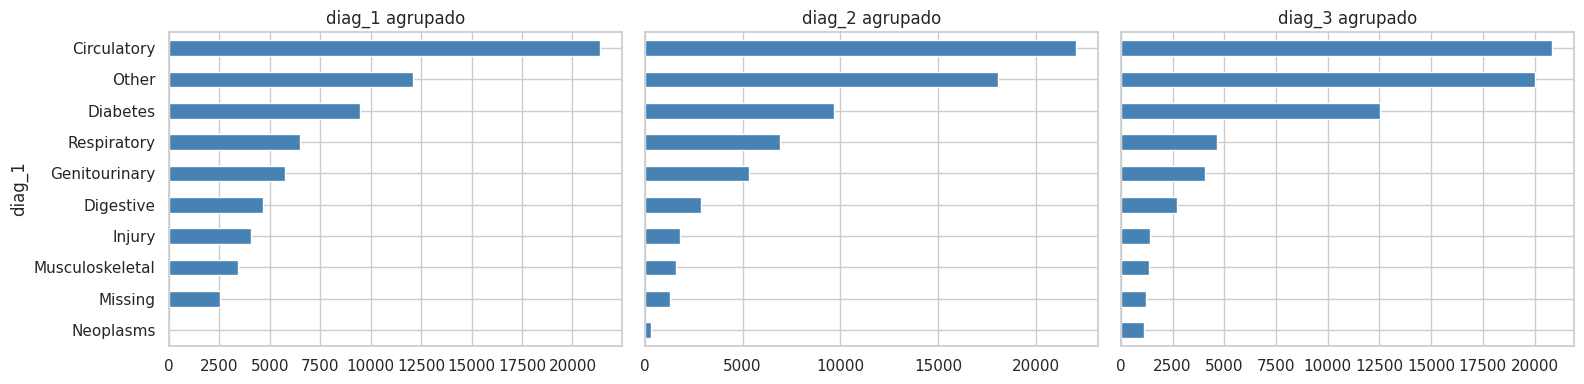

In [7]:
def map_icd9(code) -> str:
    """Mapea un código ICD-9 a la categoría clínica de Strack et al. (2014)."""
    if pd.isna(code):
        return "Missing"
    c = str(code).strip()
    if c[:1] in ("V", "E"):
        return "Other"
    try:
        n = int(float(c))
    except ValueError:
        return "Other"
    if n == 250:
        return "Diabetes"
    if 390 <= n <= 459 or n == 785:
        return "Circulatory"
    if 460 <= n <= 519 or n == 786:
        return "Respiratory"
    if 520 <= n <= 579 or n == 787:
        return "Digestive"
    if 800 <= n <= 999:
        return "Injury"
    if 710 <= n <= 739:
        return "Musculoskeletal"
    if 580 <= n <= 629 or n == 788:
        return "Genitourinary"
    if 140 <= n <= 239:
        return "Neoplasms"
    return "Other"

# Pruebas con casos conocidos
casos = {"250.83": "Diabetes", "250": "Diabetes", "428": "Circulatory", "414": "Circulatory", "785": "Circulatory",
         "486": "Respiratory", "786": "Respiratory", "575": "Digestive", "820": "Injury", "715": "Musculoskeletal",
         "585": "Genitourinary", "788": "Genitourinary", "162": "Neoplasms", "V57": "Other", "E909": "Other",
         "276": "Other", np.nan: "Missing"}
for entrada, esperado in casos.items():
    assert map_icd9(entrada) == esperado, f"{entrada!r} -> {map_icd9(entrada)} (esperado {esperado})"
print("✔ Mapeo ICD-9 verificado en", len(casos), "casos.")

for col in ["diag_1", "diag_2", "diag_3"]:
    data[col] = data[col].map(map_icd9)

fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for a, col in zip(ax, ["diag_1", "diag_2", "diag_3"]):
    data[col].value_counts().plot.barh(ax=a, color="steelblue")
    a.set_title(f"{col} agrupado"); a.invert_yaxis()
plt.tight_layout(); savefig("02_icd9_grupos"); plt.show()

## 5. Split train / test (80/20 estratificado)

Se divide **antes** de calcular cualquier estadístico aprendido. Estratificado por el target para mantener ~11% de positivos en ambos lados.

> ⚠️ **Desde esta celda, `X_test` / `y_test` NO se usan en ninguna celda** hasta §11 (donde solo se guardan en disco). Todo el análisis, el escalado, la selección y la validación usan únicamente `X_train` / `y_train`.

In [8]:
y = data[TARGET]
X = data.drop(columns=[TARGET])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Verificaciones del split
solapados = set(patient_id.loc[X_train.index]) & set(patient_id.loc[X_test.index])
assert len(solapados) == 0, "hay pacientes en train y test a la vez"
assert abs(y_train.mean() - y_test.mean()) < 0.005, "el split no quedó estratificado"

display(pd.DataFrame({
    "filas": [len(X_train), len(X_test)],
    "% reingreso <30": [y_train.mean() * 100, y_test.mean() * 100],
    "pacientes únicos": [patient_id.loc[X_train.index].nunique(), patient_id.loc[X_test.index].nunique()],
}, index=["train", "test (congelado)"]).round(2))
print("✔ Sin pacientes compartidos entre train y test; proporciones del target equivalentes.")

# Tipos de columnas
NUMERIC = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
           "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses", "age_ord"]
CATEGORICAL = [c for c in X_train.columns if c not in NUMERIC]
print(f"\n{len(NUMERIC)} numéricas | {len(CATEGORICAL)} categóricas")

,filas,% reingreso <30,pacientes únicos
train,55976,8.97,55976
test (congelado),13994,8.97,13994


✔ Sin pacientes compartidos entre train y test; proporciones del target equivalentes.

9 numéricas | 33 categóricas


## 6. Análisis de los datos (solo *train*)

Todo lo que sigue usa **únicamente `X_train`**. Es la versión del análisis que puede sustentar decisiones de modelado; el EDA general (`01_eda`) queda como exploración.

Tasa base de reingreso <30 días en train: 8.97%


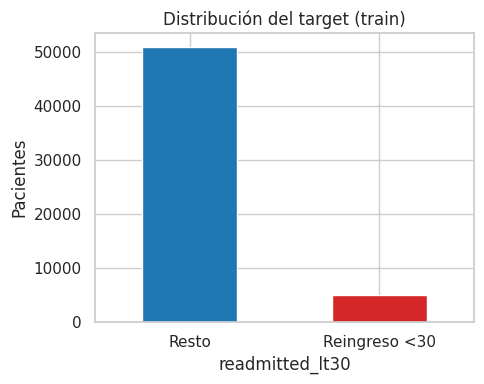

In [9]:
train = X_train.assign(**{TARGET: y_train})
base_rate = y_train.mean()
print(f"Tasa base de reingreso <30 días en train: {base_rate:.2%}")

fig, ax = plt.subplots(figsize=(5, 4))
y_train.map({0: "Resto", 1: "Reingreso <30"}).value_counts().plot.bar(ax=ax, color=["#1f77b4", "#d62728"])
ax.set_title("Distribución del target (train)"); ax.set_ylabel("Pacientes"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); savefig("02_target"); plt.show()

**Lectura:** el desbalance es fuerte (~9% positivos tras los filtros; baja de 11% porque el primer encuentro de cada paciente reingresa menos que los siguientes). Un modelo que siempre prediga "no reingresa" tendría ~91% de *accuracy* sin servir de nada → **accuracy no es una métrica válida aquí** (ver §9).

### 6.1 Faltantes en *train* (tras la carga correcta)

In [10]:
miss = (X_train.isna().mean() * 100).round(2)
miss = miss[miss > 0].sort_values(ascending=False).to_frame("% faltante")
display(miss)

,% faltante
medical_specialty,48.17
race,2.71


**Decisión:** los faltantes categóricos (`medical_specialty`, `race`, `diag_*`) se imputan con la categoría explícita `"Missing"` (en lugar de la moda), porque que el dato falte puede ser informativo y la moda inventaría información. Las numéricas se imputan con la mediana (en la práctica no tienen faltantes, pero el Pipeline queda robusto a datos nuevos).

### 6.2 Variables numéricas: distribución

,media,mediana,desv,min,p99,max,skew,kurtosis
time_in_hospital,4.27,3.0,2.93,1,13.0,14,1.18,1.02
num_lab_procedures,42.88,44.0,19.93,1,85.0,132,-0.22,-0.30
num_procedures,1.42,1.0,1.76,0,6.0,6,1.24,0.59
num_medications,15.68,14.0,8.30,1,44.0,81,1.43,3.80
number_outpatient,0.28,0.0,1.04,0,4.0,36,9.27,164.66
number_emergency,0.11,0.0,0.53,0,2.0,42,22.83,1295.78
number_inpatient,0.18,0.0,0.61,0,3.0,12,5.70,49.48
number_diagnoses,7.22,8.0,2.01,1,9.0,16,-0.72,-0.36
age_ord,6.04,6.0,1.60,0,9.0,9,-0.63,0.35


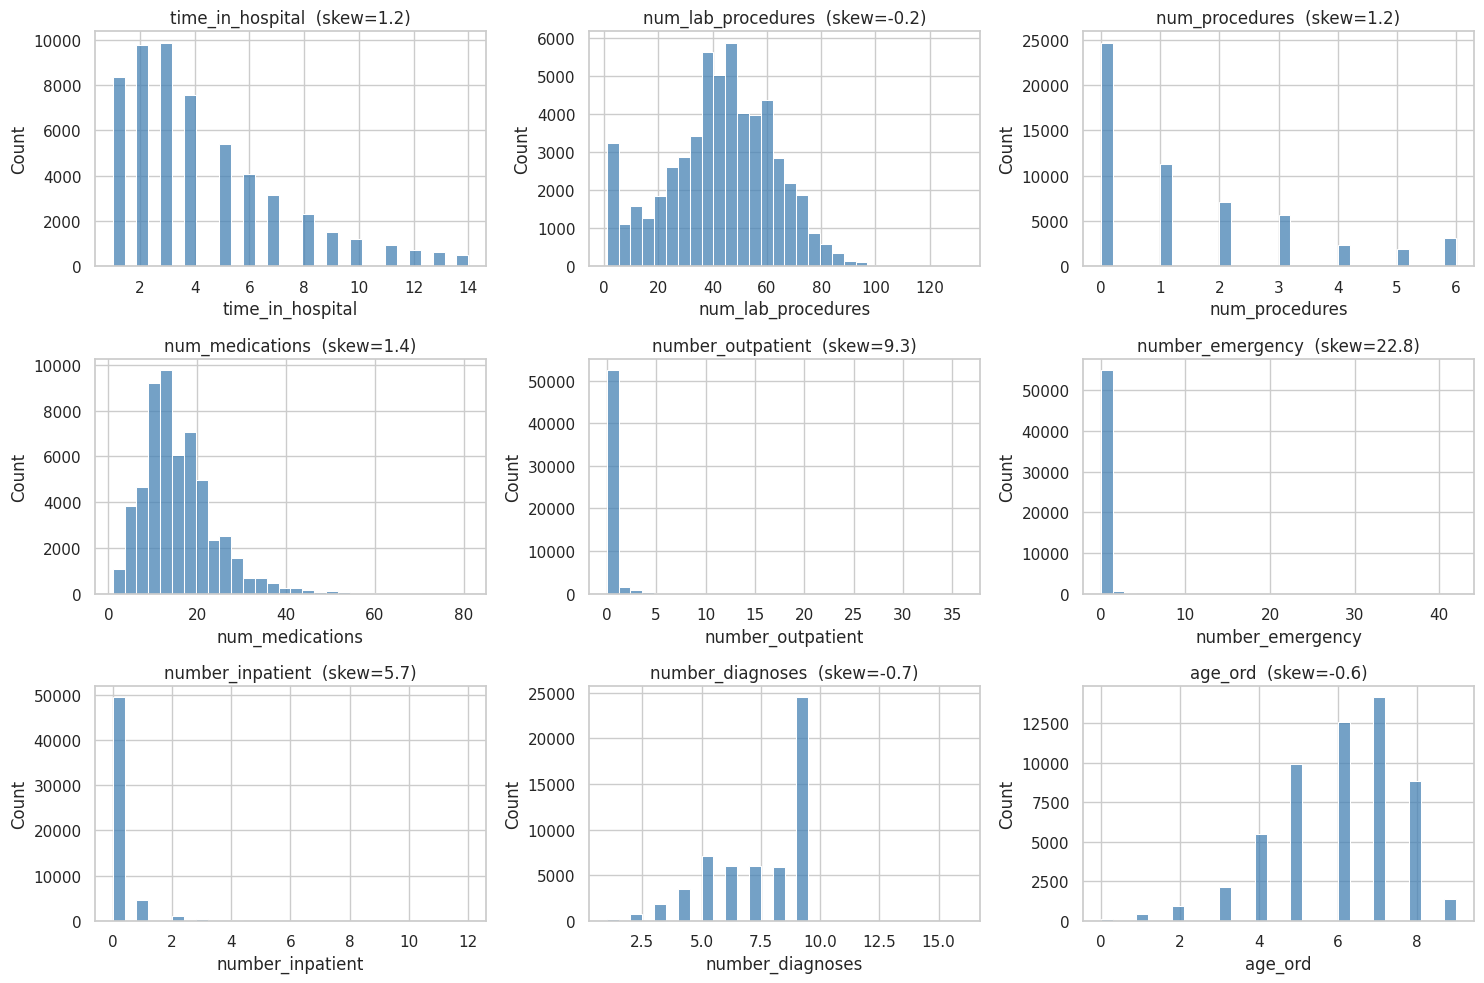

In [11]:
resumen_num = pd.DataFrame({
    "media": train[NUMERIC].mean(), "mediana": train[NUMERIC].median(), "desv": train[NUMERIC].std(),
    "min": train[NUMERIC].min(), "p99": train[NUMERIC].quantile(0.99), "max": train[NUMERIC].max(),
    "skew": train[NUMERIC].skew(), "kurtosis": train[NUMERIC].kurt(),
}).round(2)
display(resumen_num)

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.flat, NUMERIC):
    sns.histplot(train[col], bins=30, ax=ax, color="steelblue")
    ax.set_title(f"{col}  (skew={train[col].skew():.1f})")
plt.tight_layout(); savefig("02_numericas_hist"); plt.show()

**Lectura:** los conteos de visitas previas (`number_outpatient`, `number_emergency`, `number_inpatient`) son muy asimétricos, con una barra enorme en 0 y una cola larga. `num_medications` y `num_procedures` tienen asimetría moderada. Esto condiciona el escalado (§7).

### 6.3 Correlación entre numéricas (Spearman)

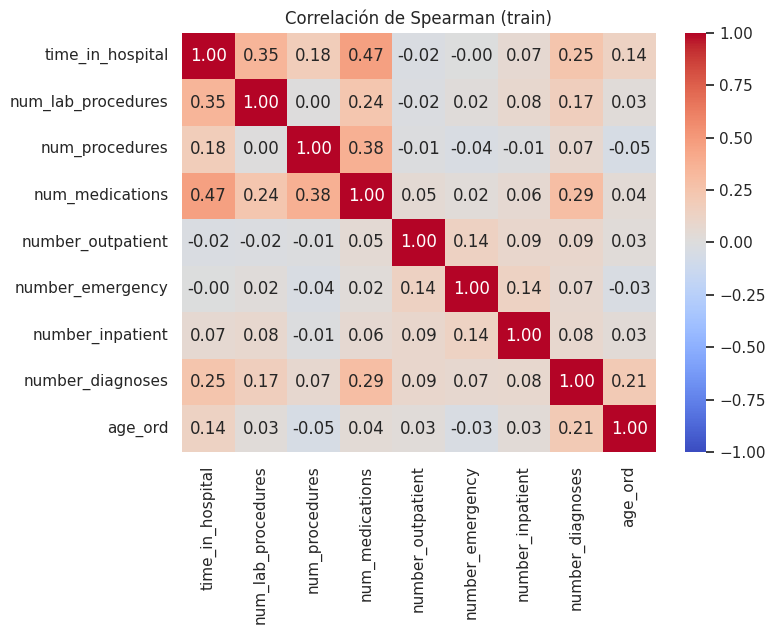

Pares con |rho| >= 0.5:


,,rho


In [12]:
corr = train[NUMERIC].corr(method="spearman")
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlación de Spearman (train)")
plt.tight_layout(); savefig("02_correlacion"); plt.show()

pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
altos = pares[pares.abs() >= 0.5].sort_values(key=abs, ascending=False)
print("Pares con |rho| >= 0.5:"); display(altos.to_frame("rho").round(2))

**Lectura:** se usa Spearman (no Pearson) porque las variables son asimétricas y con outliers. Ningún par de numéricas llega a |rho| = 0.5, así que no hay redundancia fuerte entre ellas y no se elimina ninguna por este criterio.

### 6.4 Tasa de reingreso por nivel de variables clave

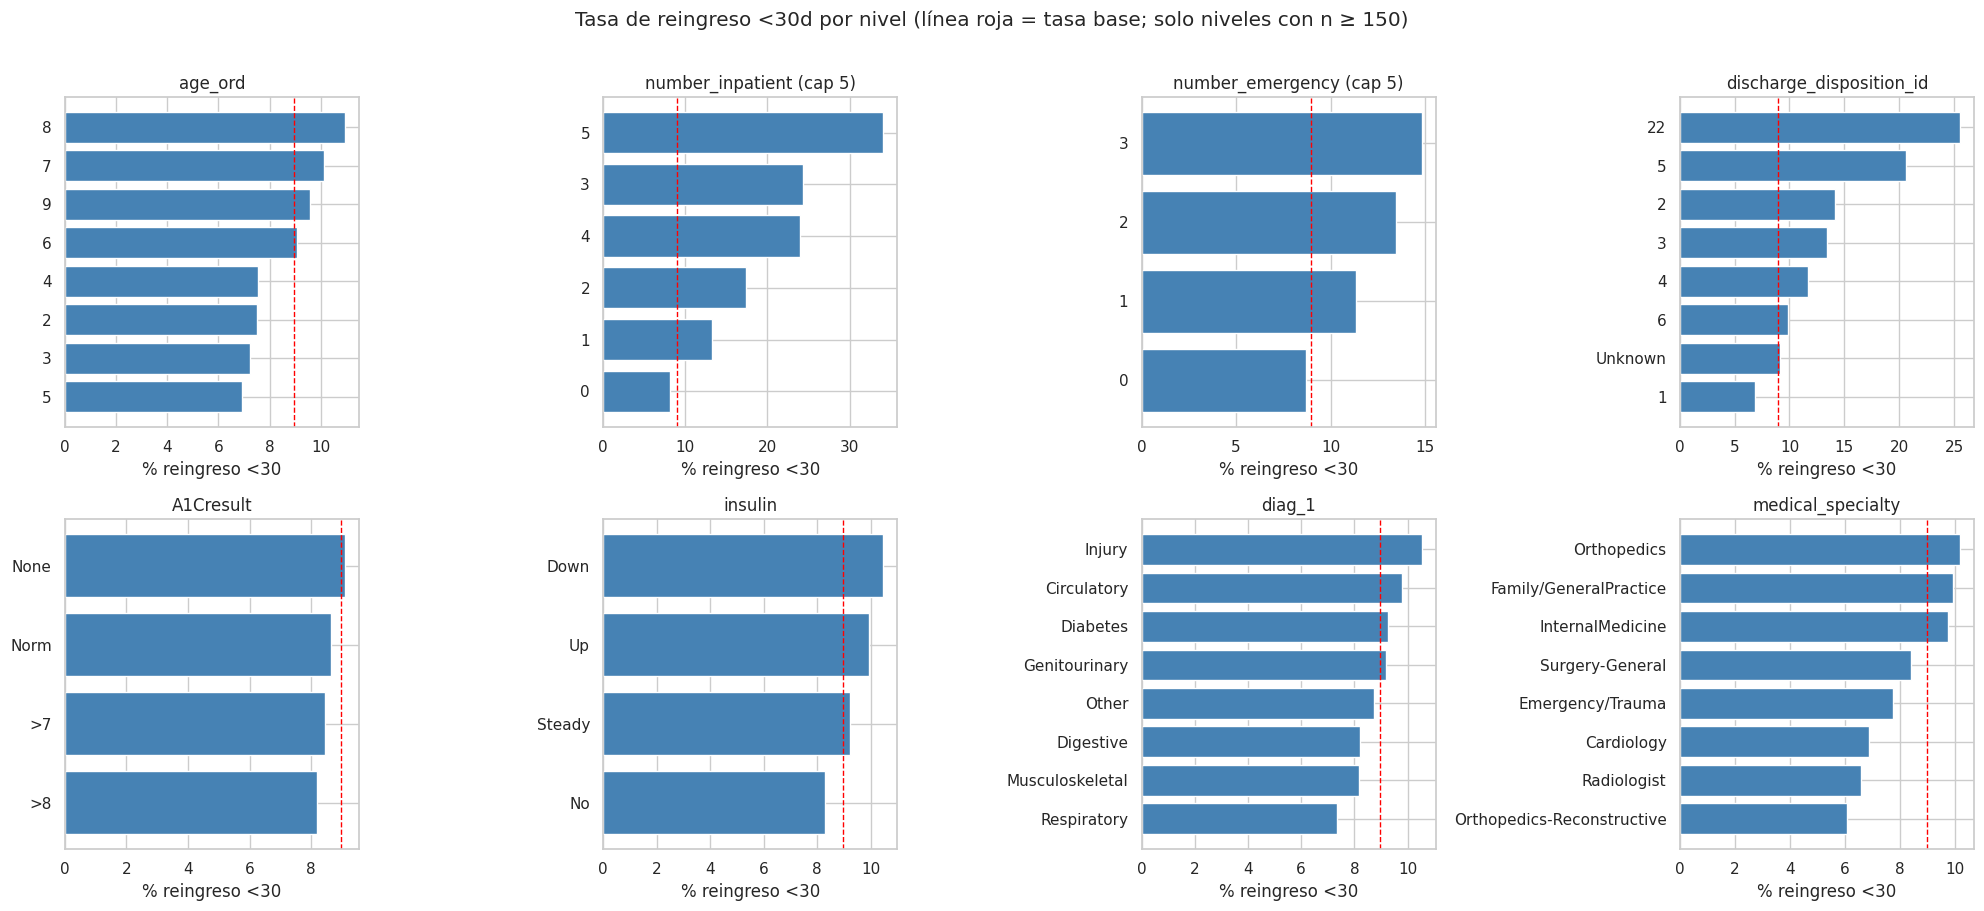

In [13]:
view = train.copy()
view["number_inpatient (cap 5)"] = view["number_inpatient"].clip(upper=5)
view["number_emergency (cap 5)"] = view["number_emergency"].clip(upper=5)

def plot_rate(ax, col, top=8, min_n=150):
    g = view.groupby(col)[TARGET].agg(["mean", "size"])
    g = g[g["size"] >= min_n].sort_values("size", ascending=False).head(top).sort_values("mean")
    ax.barh(g.index.astype(str), g["mean"] * 100, color="steelblue")
    ax.axvline(base_rate * 100, color="red", ls="--", lw=1)
    ax.set_title(col); ax.set_xlabel("% reingreso <30")

vars_clave = ["age_ord", "number_inpatient (cap 5)", "number_emergency (cap 5)", "discharge_disposition_id",
              "A1Cresult", "insulin", "diag_1", "medical_specialty"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, vars_clave):
    plot_rate(ax, col)
plt.suptitle("Tasa de reingreso <30d por nivel (línea roja = tasa base; solo niveles con n ≥ 150)", y=1.01)
plt.tight_layout(); savefig("02_tasa_por_nivel"); plt.show()

**Cómo leerlo:** barras a la derecha de la línea roja = niveles con más riesgo que el promedio. Es la forma más directa de ver señal predictiva en conteos donde las medianas por grupo son idénticas (0 vs 0) y por eso Mann-Whitney sobre medianas no dice mucho.

**Qué se ve (con `RANDOM_STATE = 42`):** el riesgo sube de forma casi monótona con las hospitalizaciones previas (≈8% con 0 vs. más de 30% con 5 o más) y con las visitas previas a urgencias; `discharge_disposition_id` separa fuerte (los códigos 22 = rehabilitación y 5 = otra institución hospitalaria superan el 20%, mientras que 1 = alta a casa queda bajo la tasa base); y quienes tienen `A1Cresult` medido reingresan *menos* que los no medidos, un efecto pequeño. Los códigos de `discharge_disposition_id` se traducen con `IDS_mapping.csv`.

### 6.5 Ranking univariado de relevancia (solo *train*)

- **Información mutua** para numéricas (captura relaciones no lineales).
- **Cramér's V corregido por sesgo** para categóricas (el χ² crudo crece con *n* y con el número de categorías; V lo normaliza a 0–1).

Esto es un **filtro exploratorio** (mira cada variable por separado). La selección definitiva (§8) usa un criterio multivariado con validación cruzada.

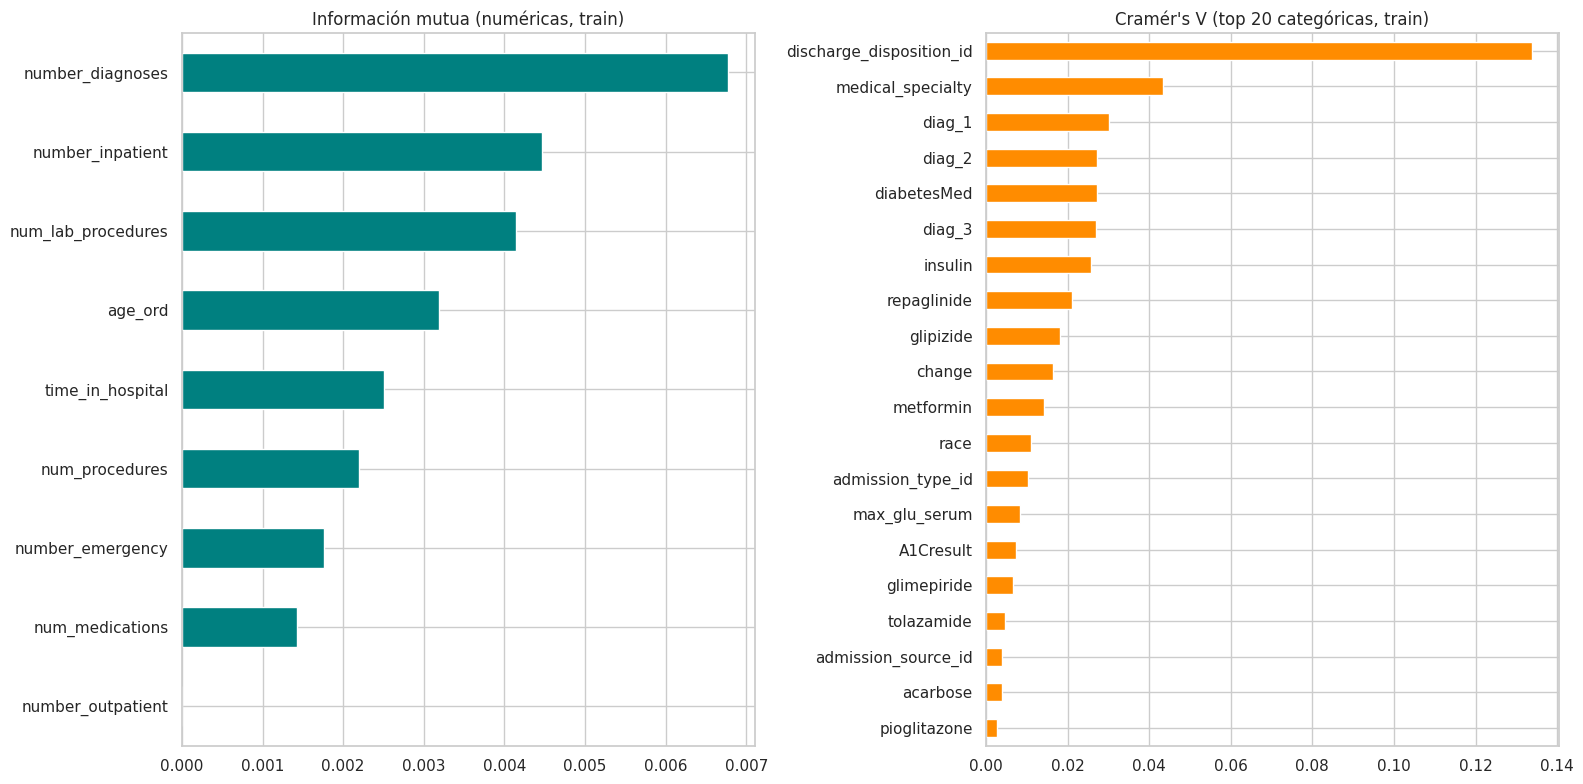

,MI (numéricas),Cramér V (categóricas)
number_diagnoses,0.0068,NaN
number_inpatient,0.0045,NaN
num_lab_procedures,0.0041,NaN
age_ord,0.0032,NaN
time_in_hospital,0.0025,NaN
discharge_disposition_id,NaN,0.134
medical_specialty,NaN,0.043
diag_1,NaN,0.030
diag_2,NaN,0.027
diabetesMed,NaN,0.027


In [14]:
def cramers_v(x: pd.Series, y: pd.Series) -> float:
    """Cramér's V con corrección de sesgo (Bergsma 2013)."""
    ct = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.to_numpy().sum()
    r, k = ct.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / max(1e-12, min(kc - 1, rc - 1))))

mi = pd.Series(mutual_info_classif(train[NUMERIC], y_train, discrete_features=False, random_state=RANDOM_STATE),
               index=NUMERIC).sort_values(ascending=False)
cv = pd.Series({c: cramers_v(train[c].fillna("Missing"), y_train) for c in CATEGORICAL}).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 8))
mi.sort_values().plot.barh(ax=ax[0], color="teal"); ax[0].set_title("Información mutua (numéricas, train)")
cv.head(20).sort_values().plot.barh(ax=ax[1], color="darkorange"); ax[1].set_title("Cramér's V (top 20 categóricas, train)")
plt.tight_layout(); savefig("02_ranking_univariado"); plt.show()
display(pd.concat([mi.rename("MI (numéricas)").round(4).head(5), cv.rename("Cramér V (categóricas)").round(3).head(8)], axis=1))

**Advertencia:** asociación ≠ causalidad ni ≠ poder predictivo en conjunto. Variables como `discharge_disposition_id` pueden correlacionar con reingreso por cómo se organiza el egreso, no porque "causen" el reingreso. Todos los valores de V son bajos en términos absolutos: **es normal en este dataset** (la señal es débil y distribuida, y por eso el rendimiento esperado es modesto).

## 7. Escalado de las variables numéricas

**Qué se decide y por qué:**

| Decisión | Razón |
|---|---|
| Transformar con `log1p` las numéricas **muy asimétricas** (skew > 1, calculado en *train*) | `log1p(x) = log(1+x)` es válido con ceros (los conteos tienen muchos) y reduce la cola larga; sin esto, pocos valores extremos dominan la escala |
| Luego `StandardScaler` (media 0, desv 1) | SVM y regresión logística son sensibles a la escala; GNB asume formas gaussianas, y una variable estandarizada y menos asimétrica se acerca más a esa suposición |
| **No** `RobustScaler` | Los conteos tienen IQR = 0 (Q1 = Q3 = 0), así que dividir por el IQR no escala nada y deja los valores extremos enormes (se muestra abajo) |
| Mismo preprocesador para los 4 modelos | Árboles y RF no necesitan escalado (es invariante), pero usar el mismo pipeline hace la comparación justa y simple |
| Los parámetros (media, desviación) se **aprenden solo en *train*** y se aplican al resto | Es la regla anti-leakage del escalado |

In [15]:
skew_tbl = pd.DataFrame({"skew": train[NUMERIC].skew()})
SKEW_THRESHOLD = 1.0
NUMERIC_SKEWED = skew_tbl.index[skew_tbl["skew"] > SKEW_THRESHOLD].tolist()
NUMERIC_PLAIN = [c for c in NUMERIC if c not in NUMERIC_SKEWED]
assert (train[NUMERIC_SKEWED].min() >= 0).all(), "log1p requiere valores >= 0"

def max_abs_z(s: pd.Series) -> float:
    return float(((s - s.mean()) / s.std()).abs().max())

cmp_esc = pd.DataFrame({
    "skew crudo": train[NUMERIC_SKEWED].skew(),
    "skew tras log1p": np.log1p(train[NUMERIC_SKEWED]).skew(),
    "IQR crudo (Q3-Q1)": train[NUMERIC_SKEWED].quantile(0.75) - train[NUMERIC_SKEWED].quantile(0.25),
    "máx |z| (Standard, crudo)": train[NUMERIC_SKEWED].apply(max_abs_z),
    "máx |z| (Standard, tras log1p)": np.log1p(train[NUMERIC_SKEWED]).apply(max_abs_z),
}).round(2)
print("Numéricas con transformación log1p:", NUMERIC_SKEWED)
print("Numéricas solo estandarizadas:   ", NUMERIC_PLAIN)
display(cmp_esc)

Numéricas con transformación log1p: ['time_in_hospital', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient']
Numéricas solo estandarizadas:    ['num_lab_procedures', 'number_diagnoses', 'age_ord']


,skew crudo,skew tras log1p,IQR crudo (Q3-Q1),"máx |z| (Standard, crudo)","máx |z| (Standard, tras log1p)"
time_in_hospital,1.18,0.13,4.0,3.32,2.23
num_procedures,1.24,0.46,2.0,2.61,1.95
num_medications,1.43,-0.44,10.0,7.86,3.97
number_outpatient,9.27,3.15,0.0,34.32,9.23
number_emergency,22.83,4.29,0.0,78.88,16.04
number_inpatient,5.70,3.15,0.0,19.51,8.31


**Lectura de la tabla:** `log1p` reduce el *skew* y los valores extremos estandarizados (máx |z|) en todas las variables transformadas. Donde `IQR = 0`, `RobustScaler` es inaplicable. Esa es la evidencia que respalda la decisión.

**Límite a declarar:** en los tres conteos de visitas previas el *skew* baja pero **no desaparece** (sigue en ~3-4) porque son datos con muchísimos ceros (*zero-inflated*): `log1p` atenúa la cola, no la vuelve gaussiana. Esto afecta sobre todo a **GNB** (asume normalidad por variable), y es una razón válida para explicar si GNB rinde peor que el resto; DT y RF no se ven afectados por la forma de la distribución.

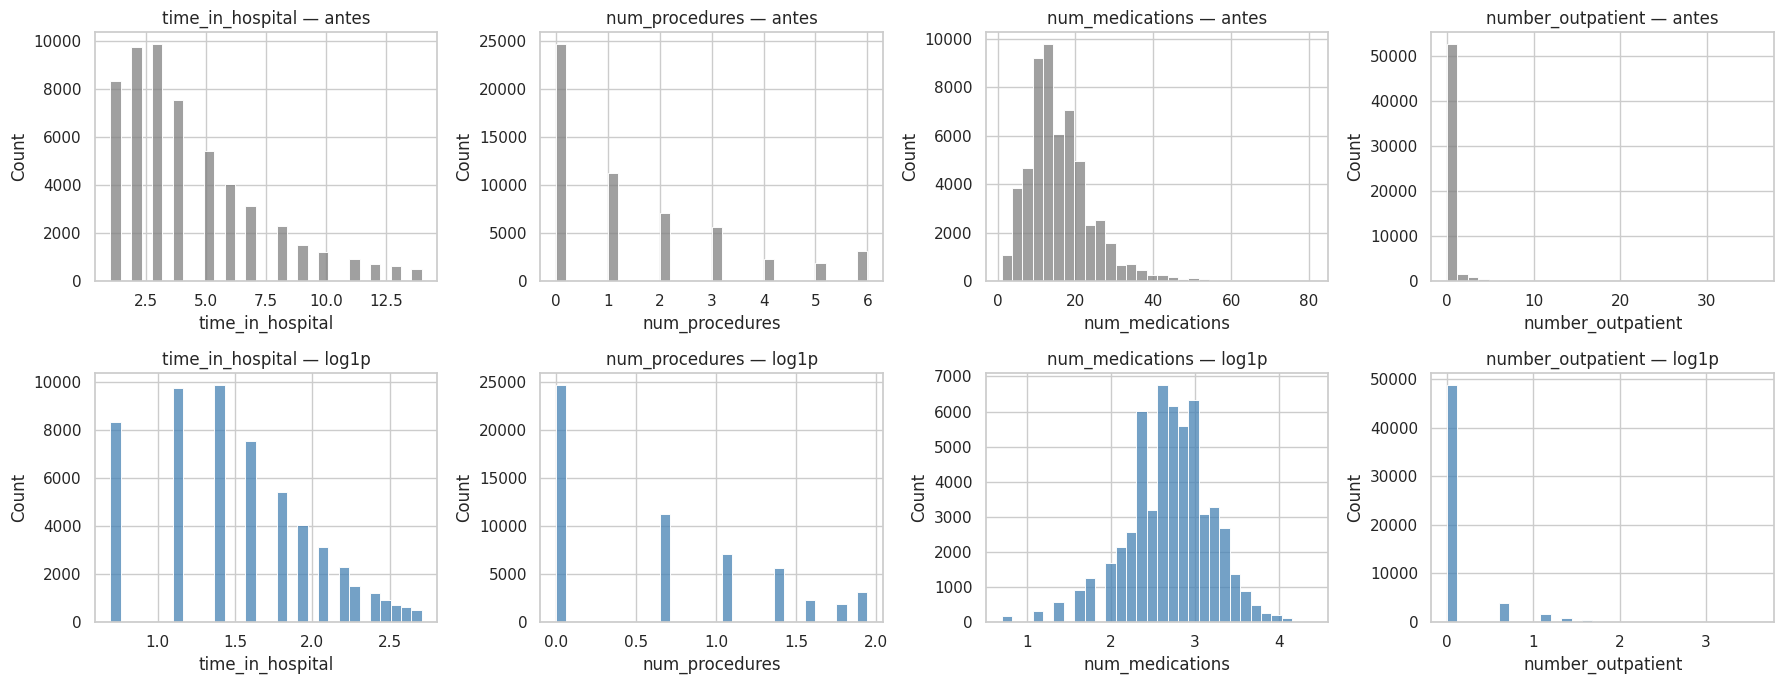

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, col in enumerate(NUMERIC_SKEWED[:4]):
    sns.histplot(train[col], bins=30, ax=axes[0, j], color="gray"); axes[0, j].set_title(f"{col} — antes")
    sns.histplot(np.log1p(train[col]), bins=30, ax=axes[1, j], color="steelblue"); axes[1, j].set_title(f"{col} — log1p")
for ax in axes.flat[len(NUMERIC_SKEWED[:4]):4]:
    ax.axis("off")
plt.tight_layout(); savefig("02_escalado_antes_despues"); plt.show()

### 7.1 El preprocesador completo

`ColumnTransformer` con tres bloques. Todo se ajusta con `fit` **solo sobre *train***:

- **Numéricas asimétricas:** imputar mediana → `log1p` → `StandardScaler`.
- **Numéricas restantes (incluye `age_ord`):** imputar mediana → `StandardScaler`.
- **Categóricas:** imputar `"Missing"` → *one-hot* con `min_frequency=0.01` (las categorías con <1% de *train* se agrupan en "infrequent"; así `medical_specialty` y los códigos raros no explotan la dimensionalidad, y esa agrupación **se aprende en *train***) y `handle_unknown="infrequent_if_exist"` (categorías nuevas no rompen la predicción). Salida **densa** porque `GaussianNB` no acepta matrices dispersas.

In [17]:
def build_preprocessor(numeric_skewed, numeric_plain, categorical) -> ColumnTransformer:
    skewed = Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("sc", StandardScaler()),
    ])
    plain = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat = Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False)),
    ])
    transformers = []
    if numeric_skewed:
        transformers.append(("skewed", skewed, list(numeric_skewed)))
    if numeric_plain:
        transformers.append(("num", plain, list(numeric_plain)))
    if categorical:
        transformers.append(("cat", cat, list(categorical)))
    return ColumnTransformer(transformers, verbose_feature_names_out=False)

pre_demo = build_preprocessor(NUMERIC_SKEWED, NUMERIC_PLAIN, CATEGORICAL).fit(X_train)   # fit SOLO con train
Z_train = pd.DataFrame(pre_demo.transform(X_train), columns=pre_demo.get_feature_names_out(), index=X_train.index)
print(f"Matriz transformada de train: {Z_train.shape[0]:,} filas × {Z_train.shape[1]} columnas | NaN: {int(Z_train.isna().sum().sum())}")

sk = pre_demo.named_transformers_["skewed"]["sc"]
pl = pre_demo.named_transformers_["num"]["sc"]
params = pd.DataFrame({
    "columna": NUMERIC_SKEWED + NUMERIC_PLAIN,
    "transformación": ["log1p + StandardScaler"] * len(NUMERIC_SKEWED) + ["StandardScaler"] * len(NUMERIC_PLAIN),
    "media aprendida (train)": [*sk.mean_, *pl.mean_],
    "desv. aprendida (train)": [*sk.scale_, *pl.scale_],
}).round(3)
display(params)

chequeo = Z_train[NUMERIC_SKEWED + NUMERIC_PLAIN].agg(["mean", "std"]).T.round(3)
print("Verificación: tras escalar, cada numérica tiene media≈0 y desv≈1 en train"); display(chequeo.T)

Matriz transformada de train: 55,976 filas × 140 columnas | NaN: 0


,columna,transformación,media aprendida (train),desv. aprendida (train)
0,time_in_hospital,log1p + StandardScaler,1.520,0.532
1,num_procedures,log1p + StandardScaler,0.652,0.664
2,num_medications,log1p + StandardScaler,2.695,0.504
3,number_outpatient,log1p + StandardScaler,0.133,0.377
4,number_emergency,log1p + StandardScaler,0.061,0.231
5,number_inpatient,log1p + StandardScaler,0.101,0.296
6,num_lab_procedures,StandardScaler,42.875,19.925
7,number_diagnoses,StandardScaler,7.219,2.006
8,age_ord,StandardScaler,6.039,1.601


Verificación: tras escalar, cada numérica tiene media≈0 y desv≈1 en train


,time_in_hospital,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,num_lab_procedures,number_diagnoses,age_ord
mean,-0.0,0.0,0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 8. Selección de características definitivas

Se hace en tres pasos, todos **dentro de *train*** y con validación cruzada para no filtrar información del test ni sobreajustar la selección:

1. **Filtro de casi-constantes:** se descarta una variable categórica si un solo nivel domina ≥ 99.5% de *train* (casi no tiene variación que aprender; típico de muchos fármacos).
2. **Importancia por permutación con Random Forest, por fold** (métrica: PR-AUC). Se **permutan las columnas originales** (no las dummies), así cada variable recibe una sola importancia interpretable. Para cada fold: se ajusta el pipeline completo en la parte de entrenamiento y se mide cuánto cae el PR-AUC en la parte de validación al barajar esa columna.
3. **Regla de estabilidad:** una variable se conserva si su importancia es positiva en al menos 4 de 5 folds **y** su media supera a su desviación entre folds (`media − desv > 0`). Así se evita quedarse con variables que ganan por azar en un fold.

> Este mismo procedimiento servirá luego con el **modelo ganador** (RF o SVM) para decidir qué variables entran en la **regresión logística**. Aquí RF actúa como modelo guía.

In [18]:
# 8.1 Casi-constantes (calculado en train)
dom_share = pd.Series({c: X_train[c].fillna("Missing").value_counts(normalize=True).iloc[0] for c in CATEGORICAL})
NEAR_CONSTANT = dom_share[dom_share >= 0.995].sort_values(ascending=False)
print(f"Variables casi constantes (nivel dominante ≥ 99.5%): {len(NEAR_CONSTANT)}")
display(NEAR_CONSTANT.round(4).to_frame("% nivel dominante"))

CATEGORICAL_CAND = [c for c in CATEGORICAL if c not in NEAR_CONSTANT.index]
CANDIDATES = NUMERIC + CATEGORICAL_CAND
print(f"\nCandidatas tras el filtro: {len(CANDIDATES)} ({len(NUMERIC)} numéricas + {len(CATEGORICAL_CAND)} categóricas)")

Variables casi constantes (nivel dominante ≥ 99.5%): 10


,% nivel dominante
acetohexamide,1.0000
metformin-pioglitazone,1.0000
metformin-rosiglitazone,1.0000
troglitazone,1.0000
glipizide-metformin,0.9999
tolbutamide,0.9998
miglitol,0.9997
tolazamide,0.9996
chlorpropamide,0.9990
acarbose,0.9971



Candidatas tras el filtro: 32 (9 numéricas + 23 categóricas)


In [19]:
# 8.2 Importancia por permutación con RF, dentro de CV (solo train)
def make_rf_pipeline() -> Pipeline:
    return Pipeline([
        ("pre", build_preprocessor(NUMERIC_SKEWED, NUMERIC_PLAIN, CATEGORICAL_CAND)),
        ("clf", RandomForestClassifier(n_estimators=150, min_samples_leaf=25, max_features="sqrt",
                                       class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)),
    ])

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
filas = []
for fold, (tr, va) in enumerate(skf.split(X_train, y_train), start=1):
    pipe = make_rf_pipeline().fit(X_train.iloc[tr][CANDIDATES], y_train.iloc[tr])
    res = permutation_importance(pipe, X_train.iloc[va][CANDIDATES], y_train.iloc[va], scoring="average_precision",
                                 n_repeats=PERM_REPEATS, random_state=RANDOM_STATE, n_jobs=-1)
    ap_fold = average_precision_score(y_train.iloc[va], pipe.predict_proba(X_train.iloc[va][CANDIDATES])[:, 1])
    print(f"fold {fold}: PR-AUC del RF en validación = {ap_fold:.3f}")
    filas += [{"fold": fold, "variable": v, "importancia": m} for v, m in zip(CANDIDATES, res.importances_mean)]

imp = pd.DataFrame(filas)
resumen = imp.groupby("variable")["importancia"].agg(media="mean", desv="std", folds_positivos=lambda s: int((s > 0).sum()))
resumen["media−desv"] = resumen["media"] - resumen["desv"]
resumen["seleccionada"] = (resumen["folds_positivos"] >= N_FOLDS - 1) & (resumen["media−desv"] > 0)
resumen["asoc. univariada (MI o V)"] = pd.concat([mi, cv]).reindex(resumen.index)
resumen = resumen.sort_values("media", ascending=False)
display(resumen.round(4))

fold 1: PR-AUC del RF en validación = 0.174


fold 2: PR-AUC del RF en validación = 0.160


fold 3: PR-AUC del RF en validación = 0.178


fold 4: PR-AUC del RF en validación = 0.162


fold 5: PR-AUC del RF en validación = 0.170


,media,desv,folds_positivos,media−desv,seleccionada,asoc. univariada (MI o V)
variable,,,,,,
discharge_disposition_id,0.0492,0.0052,5,0.0440,True,0.1338
number_inpatient,0.0188,0.0042,5,0.0146,True,0.0045
diag_1,0.0058,0.0013,5,0.0045,True,0.0301
number_diagnoses,0.0040,0.0008,5,0.0032,True,0.0068
medical_specialty,0.0025,0.0011,5,0.0014,True,0.0434
num_lab_procedures,0.0024,0.0010,5,0.0014,True,0.0041
age_ord,0.0023,0.0015,5,0.0008,True,0.0032
admission_source_id,0.0022,0.0005,5,0.0017,True,0.0039
admission_type_id,0.0022,0.0015,5,0.0007,True,0.0102


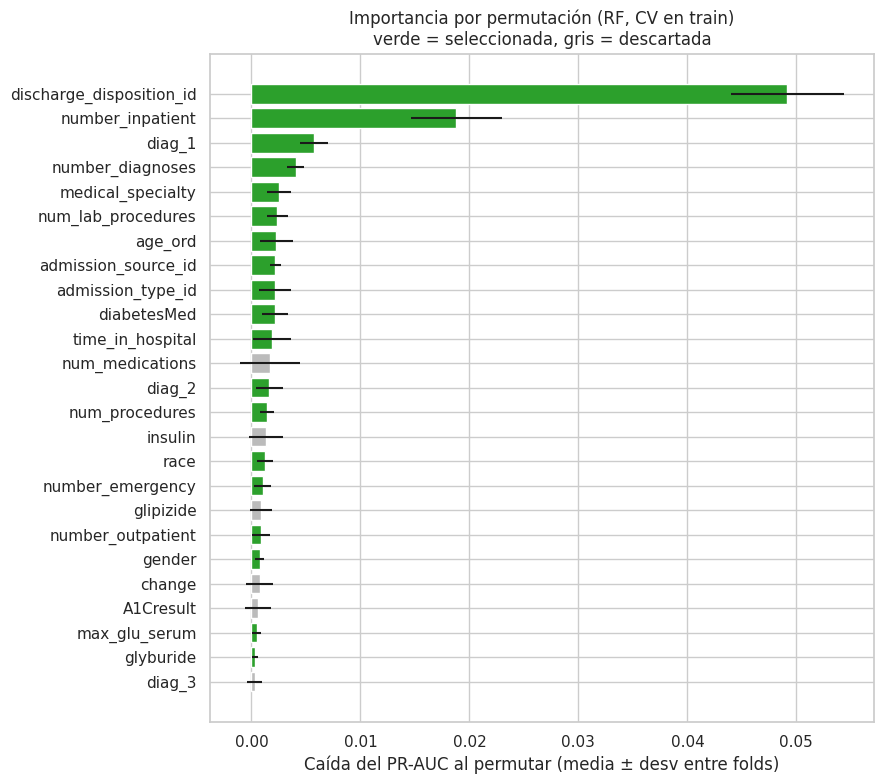

In [20]:
top = resumen.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top.index, top["media"], xerr=top["desv"], color=np.where(top["seleccionada"], "#2ca02c", "#bbbbbb"))
ax.set_xlabel("Caída del PR-AUC al permutar (media ± desv entre folds)")
ax.set_title("Importancia por permutación (RF, CV en train)\nverde = seleccionada, gris = descartada")
plt.tight_layout(); savefig("02_importancia_permutacion"); plt.show()

**Lectura:** las barras verdes son variables cuyo aporte es estable entre folds. Las grises tienen importancia cercana a 0 o inestable (positiva en un fold, negativa en otro) → son ruido para este modelo. Se comparan además con el ranking univariado: una variable con asociación univariada baja pero importancia alta en conjunto suele ser una interacción útil; una con asociación alta pero importancia ~0 suele ser redundante con otra.

In [21]:
# 8.3 Validación de la selección: regresión logística con TODAS las candidatas vs SOLO las seleccionadas
FEATURES_FINAL = resumen.index[resumen["seleccionada"]].tolist()

def lr_pipeline(features):
    sk_ = [c for c in NUMERIC_SKEWED if c in features]
    pl_ = [c for c in NUMERIC_PLAIN if c in features]
    ct_ = [c for c in CATEGORICAL_CAND if c in features]
    return Pipeline([
        ("pre", build_preprocessor(sk_, pl_, ct_)),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ])

def cv_table(features, nombre):
    r = cross_validate(lr_pipeline(features), X_train[features], y_train, cv=skf,
                       scoring={"PR-AUC": "average_precision", "ROC-AUC": "roc_auc"}, n_jobs=-1)
    return {"conjunto": nombre, "n variables": len(features),
            "PR-AUC (media ± desv)": f"{r['test_PR-AUC'].mean():.3f} ± {r['test_PR-AUC'].std():.3f}",
            "ROC-AUC (media ± desv)": f"{r['test_ROC-AUC'].mean():.3f} ± {r['test_ROC-AUC'].std():.3f}"}

validacion = pd.DataFrame([cv_table(CANDIDATES, "todas las candidatas"), cv_table(FEATURES_FINAL, "seleccionadas")])
display(validacion)
print(f"Variables descartadas ({len(CANDIDATES) - len(FEATURES_FINAL)}):", sorted(set(CANDIDATES) - set(FEATURES_FINAL)))

,conjunto,n variables,PR-AUC (media ± desv),ROC-AUC (media ± desv)
0,todas las candidatas,32,0.161 ± 0.005,0.645 ± 0.006
1,seleccionadas,19,0.161 ± 0.006,0.648 ± 0.005


Variables descartadas (13): ['A1Cresult', 'change', 'diag_3', 'glimepiride', 'glipizide', 'glyburide-metformin', 'insulin', 'metformin', 'nateglinide', 'num_medications', 'pioglitazone', 'repaglinide', 'rosiglitazone']


**Cómo interpretar:** si el PR-AUC con las seleccionadas es igual (dentro de la desviación) al de todas, la selección **redujo variables sin perder rendimiento** → un modelo más simple e interpretable.

*Salvedad honesta:* esta comparación usa los mismos folds con los que se eligieron las variables, así que es ligeramente optimista. Por eso la prueba real es el test, que se toca una sola vez al final.

## 9. Métrica objetivo

**Métrica principal: PR-AUC (*average precision*) de la clase positiva (reingreso <30 días).**

Por qué:

- Con ~9% de positivos, *accuracy* engaña (predecir siempre "no" da ~91%).
- **ROC-AUC** es útil pero optimista con clases desbalanceadas, porque los muchos negativos hacen que la tasa de falsos positivos parezca baja aunque haya muchísimos falsos positivos en términos absolutos.
- **PR-AUC** mide justo lo que importa clínicamente: de los pacientes que marcamos como riesgo, ¿cuántos realmente reingresan (precisión) y cuántos de los que reingresan detectamos (*recall*)? Su línea base es la **prevalencia** (~9%), no 0.5, así que se ve cuánto aporta el modelo sobre el azar.

**Métricas secundarias:** ROC-AUC (referencia comparable con la literatura), y *recall*/precisión/F1 en un **umbral** de decisión.
**El umbral no se fija aquí:** se elige después con predicciones *out-of-fold* del modelo ganador (nunca con el test). La tabla siguiente solo ilustra el compromiso con una regresión logística.

LogReg (baseline, predicciones out-of-fold en train): PR-AUC = 0.160 | ROC-AUC = 0.648
Azar: PR-AUC = prevalencia = 0.090 | ROC-AUC = 0.500  →  la LogReg multiplica la precisión por ~1.8x


,% de pacientes marcados como riesgo,precisión,recall,F1,lift vs azar
0,10%,0.201,0.224,0.211,2.24
1,20%,0.164,0.365,0.226,1.82
2,30%,0.142,0.474,0.218,1.58
3,40%,0.132,0.589,0.216,1.47


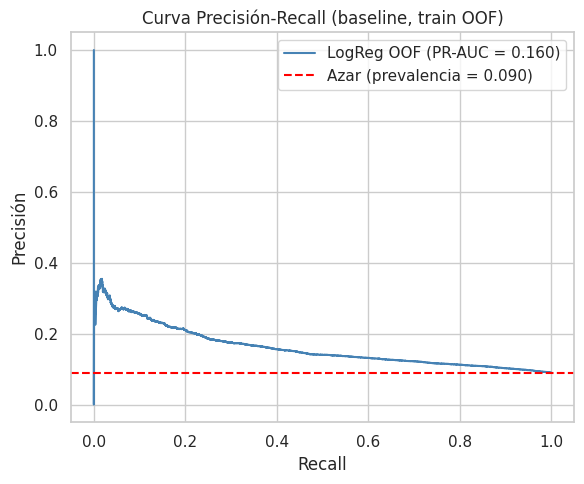

In [22]:
lr_final = lr_pipeline(FEATURES_FINAL)
oof = cross_val_predict(lr_final, X_train[FEATURES_FINAL], y_train, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
ap, auc, prev = average_precision_score(y_train, oof), roc_auc_score(y_train, oof), y_train.mean()
print(f"LogReg (baseline, predicciones out-of-fold en train): PR-AUC = {ap:.3f} | ROC-AUC = {auc:.3f}")
print(f"Azar: PR-AUC = prevalencia = {prev:.3f} | ROC-AUC = 0.500  →  la LogReg multiplica la precisión por ~{ap / prev:.1f}x")

filas = []
for frac in [0.10, 0.20, 0.30, 0.40]:
    thr = np.quantile(oof, 1 - frac)
    pred = oof >= thr
    tp = int((pred & (y_train == 1)).sum())
    precision, recall = tp / pred.sum(), tp / int((y_train == 1).sum())
    f1 = 2 * precision * recall / (precision + recall)
    filas.append({"% de pacientes marcados como riesgo": f"{frac:.0%}", "precisión": round(precision, 3),
                  "recall": round(recall, 3), "F1": round(f1, 3), "lift vs azar": round(precision / prev, 2)})
display(pd.DataFrame(filas))

p, r, _ = precision_recall_curve(y_train, oof)
plt.figure(figsize=(6, 5))
plt.plot(r, p, color="steelblue", label=f"LogReg OOF (PR-AUC = {ap:.3f})")
plt.axhline(prev, color="red", ls="--", label=f"Azar (prevalencia = {prev:.3f})")
plt.xlabel("Recall"); plt.ylabel("Precisión"); plt.title("Curva Precisión-Recall (baseline, train OOF)")
plt.legend(); plt.tight_layout(); savefig("02_pr_baseline"); plt.show()

**Lectura:** la curva por encima de la línea roja muestra que el modelo aporta señal real aunque modesta, algo esperable en este dataset (un ROC-AUC de ≈ 0.62–0.68 es el rango típico). El objetivo de los 4 modelos es **superar o igualar este baseline** en PR-AUC, y la comparación final se hace con esta misma métrica y los mismos folds.

## 10. Verificaciones anti-leakage

Comprobaciones automáticas. Si alguna falla, el notebook se detiene (`assert`).

In [23]:
SK_F = [c for c in NUMERIC_SKEWED if c in FEATURES_FINAL]
PL_F = [c for c in NUMERIC_PLAIN if c in FEATURES_FINAL]
CT_F = [c for c in CATEGORICAL_CAND if c in FEATURES_FINAL]
pre_final = build_preprocessor(SK_F, PL_F, CT_F).fit(X_train[FEATURES_FINAL])   # fit solo con train

# 1) Sin pacientes compartidos
assert not (set(patient_id.loc[X_train.index]) & set(patient_id.loc[X_test.index]))
print("✔ 1. Ningún paciente aparece en train y test.")

# 2) El target y su fuente no están entre las features
assert TARGET not in FEATURES_FINAL and "readmitted" not in FEATURES_FINAL
print("✔ 2. Ni el target ni la columna 'readmitted' están entre las features.")

# 3) Sin altas por fallecimiento/hospicio en ningún lado
terminales = {str(c) for c in TERMINAL_DISCHARGES}
assert not X_train["discharge_disposition_id"].isin(terminales).any()
assert not X_test["discharge_disposition_id"].isin(terminales).any()
print("✔ 3. No hay altas terminales en train ni test.")

# 4) Las estadísticas del escalador son las de TRAIN (no las del dataset completo)
if SK_F:
    assert np.allclose(pre_final.named_transformers_["skewed"]["sc"].mean_, np.log1p(X_train[SK_F]).mean().to_numpy())
if PL_F:
    assert np.allclose(pre_final.named_transformers_["num"]["sc"].mean_, X_train[PL_F].mean().to_numpy())
print("✔ 4. Media/desviación del escalador = estadísticos de train.")

# 5) Categorías nunca vistas no rompen la transformación
if CT_F:
    probe = X_train[FEATURES_FINAL].head(5).copy()
    probe[CT_F[0]] = "CATEGORIA_NUEVA"
    Zp = pre_final.transform(probe)
    assert np.isfinite(Zp).all()
    print(f"✔ 5. Una categoría nueva en '{CT_F[0]}' se transforma sin error.")

# 6) La salida transformada no tiene NaN
Zf = pre_final.transform(X_train[FEATURES_FINAL])
assert np.isfinite(Zf).all()
print(f"✔ 6. Matriz final de train: {Zf.shape[0]:,} × {Zf.shape[1]} sin NaN.")

✔ 1. Ningún paciente aparece en train y test.
✔ 2. Ni el target ni la columna 'readmitted' están entre las features.
✔ 3. No hay altas terminales en train ni test.
✔ 4. Media/desviación del escalador = estadísticos de train.
✔ 5. Una categoría nueva en 'race' se transforma sin error.


✔ 6. Matriz final de train: 55,976 × 76 sin NaN.


## 11. Artefactos para el siguiente notebook

Se guardan en disco (carpetas `data/processed/` y `artifacts/`, deben ir en `.gitignore` las de datos):

- `train.csv.gz` / `test.csv.gz`: datos limpios ya filtrados, con las features finales y el target. **`test.csv.gz` no se abre hasta `04_evaluation`.**
- `features_final.json`: variables elegidas, bloques (asimétricas / numéricas / categóricas), descartadas y motivo.
- `preprocessor.joblib`: `ColumnTransformer` **ajustado solo con train**.
- `config.json`: métrica objetivo, semilla y folds.

> Al leer los CSV en el siguiente notebook, las categóricas deben leerse como texto (`dtype=str` para las de `CAT_COLS` en `features_final.json`), porque `admission_type_id` y similares parecen números.

In [24]:
cols_out = FEATURES_FINAL + [TARGET]
X_train[FEATURES_FINAL].assign(**{TARGET: y_train}).to_csv(PROC / "train.csv.gz", compression="gzip")
X_test[FEATURES_FINAL].assign(**{TARGET: y_test}).to_csv(PROC / "test.csv.gz", compression="gzip")   # solo se guarda
joblib.dump(pre_final, ART / "preprocessor.joblib")

descartadas = {c: ("casi constante (≥99.5% un nivel)" if c in NEAR_CONSTANT.index else
                   "importancia inestable o nula en CV") for c in sorted(set(CATEGORICAL + NUMERIC) - set(FEATURES_FINAL))}
features_json = {
    "FEATURES_FINAL": FEATURES_FINAL,
    "NUMERIC_SKEWED_LOG1P_STD": SK_F, "NUMERIC_STD": PL_F, "CAT_COLS": CT_F,
    "TARGET": TARGET, "index": "encounter_id",
    "descartadas": descartadas,
    "n_columnas_tras_transformar": int(Zf.shape[1]),
}
(ART / "features_final.json").write_text(json.dumps(features_json, indent=2, ensure_ascii=False))
(ART / "config.json").write_text(json.dumps({
    "random_state": RANDOM_STATE, "n_folds": N_FOLDS, "metrica_principal": "average_precision",
    "metricas_secundarias": ["roc_auc", "recall@umbral", "precision@umbral", "f1@umbral"],
    "test_size": 0.2, "estratificado": True,
    "baseline_logreg_oof": {"pr_auc": round(ap, 4), "roc_auc": round(auc, 4), "prevalencia": round(prev, 4)},
}, indent=2))
for f in [PROC / "train.csv.gz", PROC / "test.csv.gz", ART / "preprocessor.joblib", ART / "features_final.json", ART / "config.json"]:
    print(f"{f.relative_to(ROOT)}  ({f.stat().st_size / 1024:.0f} KB)")

data/processed/train.csv.gz  (894 KB)
data/processed/test.csv.gz  (224 KB)
artifacts/preprocessor.joblib  (12 KB)
artifacts/features_final.json  (2 KB)
artifacts/config.json  (0 KB)


## 12. Resumen de decisiones

In [25]:
resumen_final = pd.DataFrame([
    ("Faltantes", "Solo '?' es NaN; 'None' en A1Cresult/max_glu_serum = categoría 'no medido'"),
    ("Filas", f"1 encuentro/paciente, sin altas terminales, sin género inválido → {len(data):,} filas"),
    ("Split", f"80/20 estratificado, semilla {RANDOM_STATE} → train {len(X_train):,} / test {len(X_test):,} (congelado)"),
    ("Diagnósticos", "ICD-9 → 9 categorías clínicas (Strack 2014); V/E → Other"),
    ("Escalado", f"log1p + StandardScaler en {SK_F}; StandardScaler en {PL_F}; parámetros aprendidos solo en train"),
    ("Categóricas", "imputar 'Missing' + one-hot (min_frequency=1%, categorías nuevas toleradas)"),
    ("Características", f"{len(CANDIDATES)} candidatas → {len(FEATURES_FINAL)} finales (permutación RF en CV, regla de estabilidad)"),
    ("Métrica objetivo", f"PR-AUC (baseline LogReg OOF = {ap:.3f}; azar = {prev:.3f}); ROC-AUC y recall/F1@umbral como apoyo"),
], columns=["tema", "decisión"])
pd.set_option("display.max_colwidth", 140)
display(resumen_final)

,tema,decisión
0,Faltantes,Solo '?' es NaN; 'None' en A1Cresult/max_glu_serum = categoría 'no medido'
1,Filas,"1 encuentro/paciente, sin altas terminales, sin género inválido → 69,970 filas"
2,Split,"80/20 estratificado, semilla 42 → train 55,976 / test 13,994 (congelado)"
3,Diagnósticos,ICD-9 → 9 categorías clínicas (Strack 2014); V/E → Other
4,Escalado,"log1p + StandardScaler en ['time_in_hospital', 'num_procedures', 'number_outpatient', 'number_emergency', 'number_inpatient']; StandardS..."
5,Categóricas,"imputar 'Missing' + one-hot (min_frequency=1%, categorías nuevas toleradas)"
6,Características,"32 candidatas → 19 finales (permutación RF en CV, regla de estabilidad)"
7,Métrica objetivo,PR-AUC (baseline LogReg OOF = 0.160; azar = 0.090); ROC-AUC y recall/F1@umbral como apoyo


## Conclusiones del preprocesamiento (resultados con `RANDOM_STATE = 42`)

- **Datos finales:** 69,970 encuentros (uno por paciente) → 55,976 en *train* y 13,994 en *test* (congelado); 8.97% de reingreso <30 días en ambos.
- **Faltantes:** el hallazgo clave es que `"None"` en `A1Cresult` (83%) y `max_glu_serum` (95%) no es faltante sino "no medido"; se conserva como categoría.
- **Escalado:** `log1p` + `StandardScaler` en 6 variables asimétricas y `StandardScaler` en 3; los conteos de visitas previas conservan algo de asimetría (cero-inflados).
- **Características:** de 32 candidatas (tras quitar 10 casi constantes) quedan **19 finales**, con el mismo rendimiento en validación cruzada (PR-AUC 0.161 con 32 y con 19; ROC-AUC 0.645 → 0.648). La variable más importante por mucho es `discharge_disposition_id`, seguida de `number_inpatient`.
- **Descartes que conviene discutir:** `A1Cresult`, `insulin`, `change` y `num_medications` salen por tener efecto pequeño o inestable *dado* lo demás. Que `A1Cresult` salga no contradice su relevancia clínica (es el eje del artículo de Strack et al.): la permutación mide aporte marginal y puede subestimar variables parcialmente redundantes. Si el equipo quiere mantenerla por criterio clínico, el costo esperado en rendimiento es nulo (conviene verificarlo con la misma validación cruzada).
- **Baseline:** regresión logística con PR-AUC 0.160 y ROC-AUC 0.648 (azar: 0.090 y 0.500). Es el piso que deben superar GNB, DT, RF y SVM.

## Próximos pasos

1. **`03_modeling`:** cargar `train.csv.gz` + `preprocessor` (sin tocar el test); CV estratificada con los mismos folds y semilla para **GNB, DT, RF y SVM** (+ baseline LogReg y Dummy); tuning con `RandomizedSearchCV` usando `scoring="average_precision"`; gráficas de la distribución de hiperparámetros con `cv_results_`.
2. Elegir el ganador por PR-AUC (media ± desv entre folds; si hay empate, simplicidad/tiempo) y fijar el umbral con predicciones *out-of-fold*.
3. Repetir la importancia por permutación con el **ganador** para decidir qué variables entran en la **regresión logística**.
4. **`04_evaluation`:** abrir el test **una sola vez** con el modelo final y justificar por qué es el mejor.